# Notebook 01: Thu thập và Khám phá Dữ liệu (Data Collection & Exploration)
**Đề tài:** Phân tích Sự cố Bất lợi Thuốc Thú y (OpenFDA Animal & Veterinary Adverse Events) năm 2025 và Dự báo Mức độ Nghiêm trọng năm 2026 (Q1)

**Môn học:** CSC17104 – Lập trình cho Khoa học Dữ liệu  
**Nhóm:** Global Ban  
- Đinh Công Khang (24120332)
- Trần Ngô Uyên Nhi (24120210)
- Huỳnh Tuấn Kiệt (24120356)

In [1]:
import sys
import logging
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thêm thư mục gốc vào sys.path để import các module trong src/
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# Bật log để thấy số dòng trước/sau mỗi bước (đề yêu cầu báo cáo row count)
logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s", force=True)

from src.data_loader import build_consolidated_tables, load_processed
from src.visualization import (
    set_project_plot_style,
    plot_quarterly_volume,
    plot_missing_overview,
)
set_project_plot_style()

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

---
## 1. Thu thập Dữ liệu (Data Collection)

### 1.1. Chủ đề & Bối cảnh thực tế (Subject & Real-world Context)
- **Chủ đề:** Báo cáo các biến cố/phản ứng bất lợi (Adverse Events — AE), thiếu hụt hiệu quả mong đợi (Lack of Expected Effectiveness) và lỗi chất lượng sản phẩm liên quan đến thuốc, chế phẩm sinh học và thiết bị dùng trong thú y.
- **Bối cảnh thực tế:** Giám sát cảnh giác dược thú y hậu mại (Post-market Veterinary Pharmacovigilance) giúp cơ quan quản lý (FDA CVM), bác sĩ thú y lâm sàng, hãng dược và người nuôi thú cưng/gia súc nhận diện sớm các tín hiệu rủi ro an toàn thuốc theo loài, giai đoạn tuổi, cân nặng, đường dùng và hoạt chất.

### 1.2. Tác giả, Nguồn gốc, Quần thể & Phạm vi thời gian (Author, Provenance, Population & Period)
- **Tác giả / Tổ chức thu thập & phát hành:** **U.S. Food and Drug Administration (FDA) – Center for Veterinary Medicine (CVM)** (trực thuộc Bộ Y tế và Dịch vụ Nhân sinh Hoa Kỳ — HHS). Dữ liệu xuất phát từ hệ thống cơ sở dữ liệu quốc gia **CVM Adverse Drug Experience (ADE)** và được chuẩn hóa, phân phối qua nền tảng **openFDA** (`animalandveterinary/event`).
- **Cổng tải & Manifest chính thức:**
  - Trang tải dữ liệu hàng loạt: [openFDA Animal & Veterinary Adverse Events Downloads](https://open.fda.gov/data/downloads/)
  - Manifest JSON (chứa đường dẫn phân vùng quý, `export_date`, số bản ghi): [`https://api.fda.gov/download.json`](https://api.fda.gov/download.json)
  - Đặc tả Schema & API: [openFDA Animal & Veterinary API Documentation](https://open.fda.gov/apis/animalandveterinary/event/)
- **Quần thể & Đơn vị quan sát (Population & Unit of Observation):**
  - *Quần thể mục tiêu:* Các trường hợp động vật (thú cưng như Chó, Mèo; ngựa; gia súc, gia cầm và các loài khác) sử dụng thuốc/chế phẩm thú y (chủ yếu lưu hành tại Hoa Kỳ hoặc do nhà sản xuất đăng ký với FDA báo cáo) gặp sự cố bất lợi hoặc kém hiệu quả và được gửi báo cáo về FDA CVM.
  - *Đơn vị quan sát:* Mỗi bản ghi (`unique_aer_id_number`) đại diện cho **1 báo cáo sự kiện bất lợi (Adverse Event Report)** — thường ứng với 1 cá thể bệnh (ở thú cưng) hoặc 1 đàn/nhóm vật nuôi được điều trị cùng lúc (`number_of_animals_affected > 1` ở vật nuôi trang trại).
- **Phạm vi thời gian sử dụng trong đồ án (5 phân vùng quý liên tiếp `2025q1` – `2026q1`):**
  - **Tập lịch sử & huấn luyện (2025 Q1 – Q4):** Toàn bộ 4 phân vùng quý của năm 2025 (`2025q1`–`2025q4`), dùng để phân tích chuyên sâu Q1–Q5 và huấn luyện/kiểm định chéo mô hình Học máy (Q6).
  - **Tập kiểm thử tương lai / Out-of-Time Test (2026 Q1):** Phân vùng quý đầu năm 2026 (`2026q1`), giữ độc lập để đối chiếu sự dịch chuyển xu hướng (*data/concept drift*) và đánh giá khả năng dự báo thực tế của mô hình học máy.

### 1.3. Xác minh Giấy phép & Điều khoản sử dụng (License Verification & Terms)
- **License:** **Creative Commons CC0 1.0 Universal (Public Domain Dedication)** — xác minh tại [https://open.fda.gov/license/](https://open.fda.gov/license/), trong trường `meta.license` của mỗi file JSON gốc, và toàn văn tại [https://creativecommons.org/publicdomain/zero/1.0/](https://creativecommons.org/publicdomain/zero/1.0/). Dữ liệu thuộc phạm vi công cộng, cho phép sao chép, chuẩn hóa và phân tích tự do.
- **Terms of Service & Disclaimer:** [https://open.fda.gov/terms/](https://open.fda.gov/terms/). Theo trường `meta.disclaimer` của openFDA: dữ liệu phản ánh thông tin như được báo cáo, FDA không tự động xác minh quan hệ nhân quả của từng ca riêng lẻ và dữ liệu không dùng để thay thế tư vấn y khoa/thú y lâm sàng.

### 1.4. Phương pháp thu thập & Các hạn chế/thiên lệch đã biết (Collection Method & Known Limitations/Biases)
- **Phương pháp thu thập (Giám sát Cảnh giác dược Thú y — 2 kênh thu thập):**
  1. **Báo cáo bắt buộc từ nhà sản xuất (Mandatory Reporting — 21 CFR 514.80):** Các hãng dược và nhà tài trợ thuốc thú y được cấp phép (NADA/ANADA) bắt buộc phải báo cáo các sự cố bất lợi về FDA CVM (báo cáo khẩn 15 ngày trên **Form FDA 1932** và báo cáo định kỳ) qua cổng điện tử **FDA Electronic Submissions Gateway (ESG / ESG NextGen — Electronic Submission System)** với chuẩn bản tin **HL7 ICSR** theo hướng dẫn quốc tế **VICH GL35** (*CVM GFI #214*).
  2. **Báo cáo tự nguyện từ thực tế lâm sàng (Voluntary / Spontaneous Reporting):** Bác sĩ thú y (`Veterinarian`), chủ vật nuôi (`Animal Owner`) và nhân viên y tế khác gửi báo cáo tự nguyện bằng cách báo cho hãng sản xuất (để hãng chuyển tiếp về FDA), hoặc gửi trực tiếp cho FDA CVM qua biểu mẫu PDF **Form FDA 1932a** hay bảng câu hỏi trực tuyến **Rational Questionnaire** trên cổng **Safety Reporting Portal (SRP)**.
  3. **Chuẩn hóa thuật ngữ chuyên ngành:** Các triệu chứng/phản ứng được chuẩn hóa theo bộ từ điển **VeDDRA** (*Veterinary Dictionary for Drug Regulatory Activities*) và thuốc được phân loại theo hệ thống **ATCvet** (WHO).
- **7 Hạn chế & Thiên lệch cốt lõi (Limitations & Known Biases):**
  1. **Thiếu mẫu số phơi nhiễm (Lack of Denominator / No Exposure Data):** Dữ liệu chỉ gồm các ca **có báo cáo sự cố**, không có tổng số cá thể động vật đã dùng thuốc an toàn $\rightarrow$ **không thể tính tỷ lệ mắc bệnh tuyệt đối (incidence rate / absolute risk)**, chỉ kết luận trên tỷ trọng báo cáo hoặc Tỷ số chênh báo cáo (*Reporting Odds Ratio — ROR*).
  2. **Không thiết lập quan hệ nhân quả trực tiếp (No Proof of Causality):** Sự xuất hiện đồng thời của thuốc và phản ứng trong báo cáo chỉ phản ánh sự kết hợp về mặt thời gian (*temporal association*), không chứng minh thuốc là nguyên nhân gây ra phản ứng (có thể nhiễu bởi bệnh nền, tuổi già, hoặc tương tác đa thuốc).
  3. **Báo cáo thiếu & Thiên lệch mức độ nghiêm trọng (Under-reporting & Severity/Stimulated Reporting Bias):** Không phải mọi phản ứng phụ ngoài thực tế đều được báo cáo; các biến cố nặng (`serious_ae = true`, tử vong), thuốc vừa mới cấp phép (*Weber effect*) hoặc thuốc có cảnh báo truyền thông thường được báo cáo với tần suất cao hơn.
  4. **Thiên lệch theo loài và hành vi người báo cáo (Species & Reporter Bias):** Thú cưng (Chó, Mèo) được theo dõi cá thể hóa nên chiếm tỷ trọng áp đảo so với vật nuôi trang trại (vốn thường báo cáo gộp theo đàn `number_of_animals_affected > 1`). Bác sĩ thú y (`Veterinarian`), Chủ vật nuôi (`Animal Owner`) và Hãng dược cũng khác biệt rõ rệt về độ đầy đủ lâm sàng và độ trễ gửi báo cáo (`reporting_delay_days`).
  5. **Khử trùng lặp phòng ngừa theo `unique_aer_id_number` & Phân biệt với `report_id` (Precautionary Deduplication & Identifier Distinction):** Về mặt lý thuyết, hồ sơ có thông tin bổ sung (follow-up) có thể được cập nhật lại với cùng mã `unique_aer_id_number`. Dù kiểm tra thực tế trên các cặp quý liền kề (`2025q1` $\leftrightarrow$ `2025q2`, `2025q4` $\leftrightarrow$ `2026q1`) ghi nhận `0` bản ghi trùng `unique_aer_id_number`, `src/data_loader.py` vẫn thực hiện **khử trùng lặp phòng ngừa** theo `unique_aer_id_number` (giữ bản ở quý/file muộn nhất). Tuyệt đối **không** dedupe theo `report_id`, vì `report_id` là mã đơn đăng ký thuốc NADA/ANADA (vd: `N141302`, `N141272`) dùng chung cho nhiều ca bệnh độc lập.
  6. **Dữ liệu khuyết không ngẫu nhiên & Đơn vị đo lường hỗn hợp (Missingness & Heterogeneous Units):** Định dạng JSON đa cấp (`drug[]`, `reaction[]`, `outcome[]`), nhiều trường tùy chọn bị khuyết theo cơ chế MAR/MNAR và đơn vị tuổi/cân nặng không đồng nhất (`Day/Week/Month/Year`, `lb/oz/g/kg`).
  7. **Độ trễ đăng tải & dữ liệu theo thời điểm tải (Posting Delay & Snapshot):** openFDA cập nhật theo quý và báo cáo có thể trễ 3–6 tháng kể từ lúc FDA nhận; hồ sơ cũng có thể được bổ sung sau đó. Vì vậy phân vùng `2026q1` là ảnh chụp tại thời điểm tải (`meta.last_updated` ghi trong `data/raw/MANIFEST.json`), có thể chưa đầy đủ hoặc thay đổi nếu tải lại về sau, ảnh hưởng đến phân tích độ trễ báo cáo (Q5) và tập test của Q6.

### 1.5. Công trình/Notebook công khai liên quan & Điểm khác biệt (Declare Existing Work & Differentiation)
- **Các công trình, tài liệu và repo công khai liên quan:**
  1. **Cổng khám phá tương tác chính thức của openFDA** ([openFDA Animal & Veterinary Interactive Chart](https://open.fda.gov/apis/animalandveterinary/event/explore-the-api-with-an-interactive-chart/)): Chỉ cung cấp thống kê đếm tần suất đơn biến (top loài, top người báo cáo, top phản ứng VeDDRA).
  2. **Kho mã nguồn hạ tầng, Thư viện AI Skills & Công cụ truy vấn trên GitHub** ([`FDA/openfda`](https://github.com/FDA/openfda), [`OpenVet-Projects/VetClaw`](https://github.com/OpenVet-Projects/VetClaw), [`api-evangelist/openfda`](https://github.com/api-evangelist/openfda)): Tập trung vào hạ tầng nạp dữ liệu backend (`FDA/openfda`), thư viện kỹ năng AI thú y có tích hợp SDK client cho openFDA (`OpenVet-Projects/VetClaw`), hoặc đặc tả API/wrapper tra cứu qua REST API (`api-evangelist/openfda`).
  3. **Nghiên cứu Học máy & XAI trên dữ liệu openFDA CVM** (Sholehrasa et al., 2025 — [`arXiv:2510.01520`](https://arxiv.org/abs/2510.01520), *"Predictive Modeling and Explainable AI for Veterinary Safety Profiles, Residue Assessment, and Health Outcomes Using Real-World Data and Physicochemical Properties"*): Kết hợp dữ liệu lịch sử 1987–2025Q1 với các đặc trưng hóa lý của thuốc lấy từ PubChem (khối lượng phân tử, XLogP3, số chất nhận liên kết hydro...) để phân loại kết cục hậu nghiệm (*Death vs. Recovery*).
  4. **Các nghiên cứu Cảnh giác dược thú y chuyên biệt** (Xu et al., 2019 — *Topics in Companion Animal Medicine*, 37:100366, [`doi:10.1016/j.tcam.2019.100366`](https://doi.org/10.1016/j.tcam.2019.100366); Farrell et al., 2025 — *Frontiers in Veterinary Science*, 12:1581490, [`doi:10.3389/fvets.2025.1581490`](https://doi.org/10.3389/fvets.2025.1581490)): Xu et al. (2019) phân tích dữ liệu openFDA CVM trên Chó và Mèo nhưng tập trung vào 2 hoạt chất trị ký sinh trùng đơn lẻ (*selamectin* và *spinosad*); Farrell et al. (2025) phân tích bất cân xứng các biến cố cơ xương khớp của kháng thể đơn dòng *bedinvetmab* so với 6 thuốc đối chứng trị viêm xương khớp ở chó trên cơ sở dữ liệu **EudraVigilance Veterinary (EVV)** của EMA (2004–2024).
- **Điểm khác biệt cốt lõi của đồ án nhóm Global Ban:**
  1. **Pipeline chuẩn hóa 4 bảng phẳng & khử trùng lặp phòng ngừa:** Thiết kế `src/download_data.py` và `src/data_loader.py` có kiểm tra toàn vẹn SHA-256 và loại trùng phòng ngừa theo `unique_aer_id_number` trên giai đoạn **2025 Q1–Q4 & 2026 Q1**.
  2. **Kiểm soát biến nhiễu (D4), định lượng bất định (D5) & kiểm tra độ vững (D6):** Đối chiếu *Safety Issue* vs. *Lack Of Expected Effectiveness* bằng ROR (Q3), đánh giá tương tác *Off-label $\times$ Polypharmacy* (Q4), và phân tích độ trễ báo cáo theo đối tượng gửi (Q5).
  3. **Dự báo Triage tại thời điểm tiếp nhận với kiểm thử ngoài thời gian (Out-of-Time Split):** Dự báo trực tiếp `serious_ae` (**Train 2025 Q1–Q4 $\rightarrow$ Out-of-Time Test 2026 Q1**), loại bỏ triệt để các biến rò rỉ hậu nghiệm (`outcome`, `treated_for_ae`, `duration`).

### 1.6. Lý do chọn bộ dữ liệu (Motivation)
- Độc đáo, mang tính ứng dụng liên ngành cao (Cảnh giác Dược Thú y & Khoa học Dữ liệu), quy mô lớn (hàng chục nghìn báo cáo qua 5 quý `2025q1`–`2026q1`) và cấu trúc JSON lồng nhau giúp thể hiện trọn vẹn kỹ năng làm phẳng (flatten/normalize), tiền xử lý đơn vị sinh học và thiết kế kiểm thử theo thời gian (Temporal Validation).

In [2]:
# TODO [Giai đoạn 1]: Đọc các file JSON (2025 Q1 - 2026 Q1) từ thư mục ../data/raw/
# và tách thành 4 bảng chuẩn hóa: reports_df, drugs_df, reactions_df, outcomes_df
# Chỉ build lại khi chưa có đủ 4 CSV (đổi REBUILD = True để ép chạy lại)
REBUILD = False
csv_ready = all((PROCESSED_DIR / f"{n}.csv").exists()
                for n in ("reports", "drugs", "reactions", "outcomes"))

if REBUILD or not csv_ready:
    reports_df, drugs_df, reactions_df, outcomes_df = build_consolidated_tables(
        raw_dir=RAW_DIR, processed_dir=PROCESSED_DIR
    )
else:
    tables = load_processed(PROCESSED_DIR)          # dtype=str, ép kiểu ở bước tiền xử lý
    reports_df, drugs_df, reactions_df, outcomes_df = (
        tables["reports"], tables["drugs"], tables["reactions"], tables["outcomes"]
    )

tables = {
    "reports": reports_df,
    "drugs": drugs_df,
    "reactions": reactions_df,
    "outcomes": outcomes_df,
}

# Kiểm tra nhanh kích thước 4 bảng
for name, df in [("reports", reports_df), ("drugs", drugs_df),
                 ("reactions", reactions_df), ("outcomes", outcomes_df)]:
    print(f"{name:10s} {df.shape[0]:>9,} dòng × {df.shape[1]:>3} cột")

# Số báo cáo theo quý (kiểm tra đủ 5 quý 2025q1–2026q1)
print()
print(reports_df["quarter"].value_counts().sort_index())

# Khóa liên kết phải không trùng ở reports
assert reports_df["unique_aer_id_number"].is_unique, "reports còn unique_aer_id_number trùng!"

# Mọi dòng ở bảng con phải có báo cáo cha (không có khóa mồ côi)
for name, df in [("drugs", drugs_df), ("reactions", reactions_df), ("outcomes", outcomes_df)]:
    orphan = (~df["unique_aer_id_number"].isin(reports_df["unique_aer_id_number"])).sum()
    print(f"{name}: {orphan} dòng không có báo cáo cha")

reports       94,412 dòng ×  33 cột
drugs        174,123 dòng ×  30 cột
reactions    270,244 dòng ×   8 cột
outcomes      85,143 dòng ×   5 cột

quarter
2025q1    16458
2025q2    21732
2025q3    20843
2025q4    18072
2026q1    17307
Name: count, dtype: int64
drugs: 0 dòng không có báo cáo cha
reactions: 0 dòng không có báo cáo cha
outcomes: 0 dòng không có báo cáo cha


---
## 2. Khám phá Dữ liệu (Data Exploration)



### 2.1. Tổng quan cấu trúc và Schema
Phần này khảo sát tổng quan 4 bảng dữ liệu (`reports`, `drugs`, `reactions`, `outcomes`):
1. **Quy mô và Phân bố theo quý**: Số dòng, số cột, dung lượng bộ nhớ và tính ổn định qua 5 quý liên tiếp.
2. **Ý nghĩa một dòng và Khóa định danh**: Đơn vị quan sát ở mỗi bảng, phân biệt `unique_aer_id_number` (khóa chính dedupe) và `report_id` (mã NADA/ANADA).
3. **Kiểu dữ liệu và Đề xuất chuyển đổi / Loại bỏ**: Rà soát dtype hiện tại, các trường cần ép kiểu ngày/số/nhãn và cảnh báo rò rỉ dữ liệu.
4. **Kiểm tra trùng lặp và Dòng rỗng**: Khảo sát duplicate và dòng rỗng kèm biện giải xử lý.
5. **Toàn vẹn khóa liên kết (Foreign Key Integrity)**: Kiểm tra khóa mồ côi (orphan keys) và thống kê phân phối 1 - nhiều.
6. **Khảo sát sơ bộ Missing Data và nhãn không nhất quán**: Bức tranh khuyết tổng thể trước khi đi vào EDA chuyên sâu.

---
#### 2.1.1. Quy mô 4 Bảng Dữ liệu & Phân bố theo Quý (Shape & Temporal Distribution)


,Số dòng (Total),Số cột,2025 Q1,2025 Q2,2025 Q3,2025 Q4,2026 Q1,Bộ nhớ RAM
Bảng dữ liệu,,,,,,,,
reports,"94,412",33,"16,458","21,732","20,843","18,072","17,307",177.3 MB
drugs,"174,123",30,"32,474","38,943","37,405","33,463","31,838",259.3 MB
reactions,"270,244",8,"50,343","59,868","57,016","51,981","51,036",146.8 MB
outcomes,"85,143",5,"14,650","19,639","18,832","16,388","15,634",30.9 MB


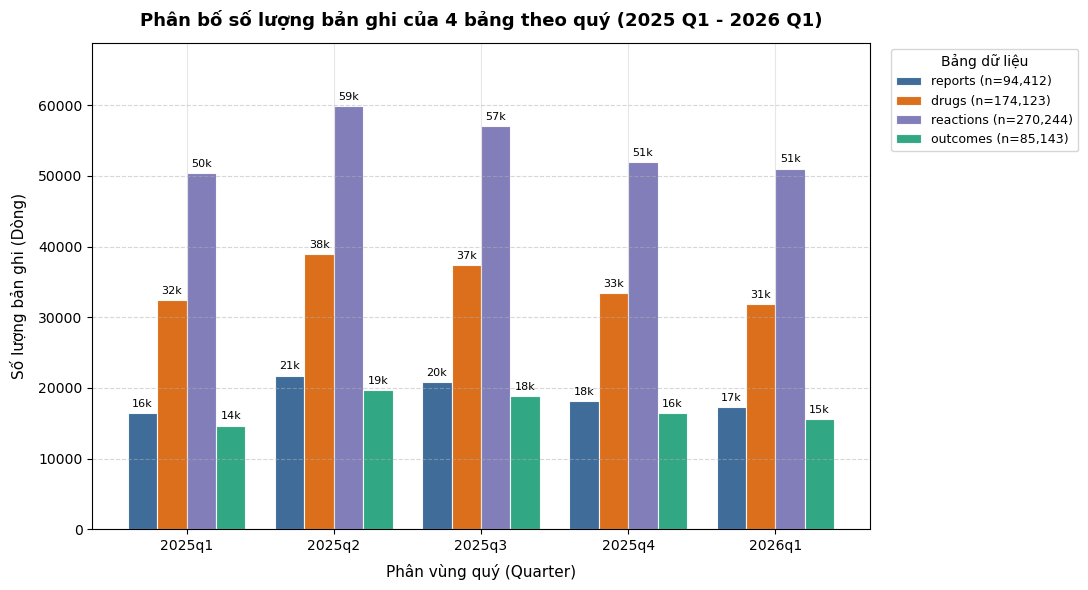

In [3]:
# Thống kê chi tiết kích thước (Shape) và phân bố bản ghi của 4 bảng qua 5 quý
rows_summary = []
for name, df in tables.items():
    q_counts = df["quarter"].value_counts()
    rows_summary.append({
        "Bảng dữ liệu": name,
        "Số dòng (Total)": f"{len(df):,}",
        "Số cột": len(df.columns),
        "2025 Q1": f"{q_counts.get('2025q1', 0):,}",
        "2025 Q2": f"{q_counts.get('2025q2', 0):,}",
        "2025 Q3": f"{q_counts.get('2025q3', 0):,}",
        "2025 Q4": f"{q_counts.get('2025q4', 0):,}",
        "2026 Q1": f"{q_counts.get('2026q1', 0):,}",
        "Bộ nhớ RAM": f"{df.memory_usage(deep=True).sum() / (1024**2):.1f} MB",
    })

shape_summary_df = pd.DataFrame(rows_summary).set_index("Bảng dữ liệu")
display(shape_summary_df)

# Trực quan hóa phân bố bản ghi của 4 bảng qua 5 quý liên tiếp
fig, ax = plot_quarterly_volume(tables)
plt.show()


**Nhận xét định lượng về quy mô và phân bố thời gian:**

1. **Quy mô dữ liệu đạt yêu cầu đề bài:**
   - Đề bài yêu cầu bộ dữ liệu tối thiểu $\approx 3,000$ dòng và $\ge 10$ cột. Dữ liệu thực tế gồm **94,412 báo cáo sự cố** (gấp $\approx 31$ lần) và 33 cột ở bảng `reports`, đảm bảo độ tin cậy thống kê cao cho mọi kiểm định.
   - Các bảng con phản ánh cấu trúc quan hệ 1 - nhiều rõ rệt: **174,123 mục thuốc** (`drugs`, trung bình $1.84$ thuốc/báo cáo), **270,244 phản ứng lâm sàng** (`reactions`, trung bình $2.86$ phản ứng/báo cáo) và **85,143 kết cục ghi nhận** (`outcomes`, trung bình $0.90$ kết cục/báo cáo).

2. **Tính ổn định và đặc điểm mùa vụ theo quý:**
   - Tập dữ liệu bao phủ 5 phân vùng quý liên tiếp với số lượng báo cáo dao động từ **16,458 đến 21,732 báo cáo/quý**.
   - Số lượng báo cáo đạt đỉnh vào **2025 Q2 (21,732 ca)** và **2025 Q3 (20,843 ca)**, sau đó giảm nhẹ vào Q4 (18,072 ca) và 2026 Q1 (17,307 ca). Điều này phản ánh rõ nét **tính mùa vụ trong y tế thú y**: mùa hè/thu là thời điểm vật nuôi hoạt động ngoài trời nhiều hơn, tần suất phơi nhiễm với ký sinh trùng (ve, bọ chét, giun tim) và nhu cầu sử dụng thuốc phòng trị tăng vọt, dẫn đến số lượng sự cố báo cáo về FDA gia tăng.

3. **Sự sẵn sàng cho chiến lược phân tách huấn luyện / kiểm thử theo thời gian (Time-based Split):**
   - **Tập train (2025 Q1–Q4):** Chiếm **77,105 báo cáo** (81.7% tổng thể), đủ lớn để trả lời trọn vẹn 5 câu hỏi phân tích chuyên sâu và 1 câu huấn luyện mô hình học máy với kỹ thuật kiểm định chéo theo thời gian (`TimeSeriesSplit`).
   - **Tập test (2026 Q1):** Chiếm **17,307 báo cáo** (18.3% tổng thể), đóng vai trò tập Test độc lập hoàn toàn để đánh giá hiệu năng thực tế của mô hình dự báo triage hồ sơ mà không bị rò rỉ dữ liệu.


---
#### 2.1.2. Ý nghĩa một dòng dữ liệu và Phân biệt Khóa định danh

Để tránh bùng nổ tổ hợp khi một báo cáo chứa nhiều thuốc, nhiều phản ứng và nhiều kết cục, dữ liệu được phân rã thành **4 bảng phẳng chuẩn hóa** với quan hệ ràng buộc khóa như sau:

| Bảng dữ liệu | Đơn vị quan sát (Một dòng đại diện cho điều gì?) | Khóa chính (PK) | Khóa ngoại (FK) | Quan hệ với `reports` |
| :--- | :--- | :--- | :--- | :---: |
| **`reports`** | **1 báo cáo sự kiện bất lợi duy nhất** gửi về FDA CVM (thường là 1 cá thể động vật, hoặc 1 đàn vật nuôi điều trị cùng đợt). | `unique_aer_id_number` | — | **Bảng cha (1)** |
| **`drugs`** | **1 mục thuốc/chế phẩm** được ghi nhận sử dụng trong đợt điều trị của báo cáo. | (`unique_aer_id_number`, `drug_idx`) | `unique_aer_id_number` | **1 — N** (Nhiều thuốc/ca) |
| **`reactions`** | **1 phản ứng/dấu hiệu lâm sàng** ghi nhận theo danh mục thuật ngữ VeDDRA. | (`unique_aer_id_number`, `veddra_term_code`) | `unique_aer_id_number` | **1 — N** (Nhiều phản ứng/ca) |
| **`outcomes`** | **1 kết cục y khoa** của con vật (`Recovered/Normal`, `Died`, `Euthanized`, `Ongoing`, `Unknown`). | (`unique_aer_id_number`, `medical_status`) | `unique_aer_id_number` | **1 — N** (Nhiều kết cục/ca) |


In [4]:
# 1. Kiểm tra tính duy nhất của unique_aer_id_number ở bảng reports
reports_df = tables["reports"]
n_total = len(reports_df)
n_unique_aer = reports_df["unique_aer_id_number"].nunique()
n_unique_rep_id = reports_df["report_id"].nunique()
n_rep_id_missing = reports_df["report_id"].isna().sum()

print("=== ĐỐI CHIẾU HAI TRƯỜNG ĐỊNH DANH TRONG BẢNG REPORTS ===")
print(f"Tổng số dòng trong bảng reports:            {n_total:,}")
print(f"Số mã unique_aer_id_number phân biệt:       {n_unique_aer:,} (Tỷ lệ duy nhất: {n_unique_aer/n_total*100:.1f}%)")
print(f"Số mã report_id phân biệt:                  {n_unique_rep_id:,} (Số dòng khuyết: {n_rep_id_missing:,})")

# 2. Thống kê Top 5 mã report_id xuất hiện nhiều lần nhất
top_rep_ids = reports_df["report_id"].value_counts().head(5)
top_rep_df = pd.DataFrame({
    "Mã NADA/ANADA (report_id)": top_rep_ids.index,
    "Số báo cáo độc lập cùng mã": top_rep_ids.values,
    "Tỷ lệ trên toàn bộ dữ liệu (%)": (top_rep_ids.values / n_total * 100).round(2)
})
print("\n=== TOP 5 MÃ REPORT_ID XUẤT HIỆN NHIỀU NHẤT ===")
display(top_rep_df)

# 3. Minh chứng thực nghiệm: 3 ca bệnh khác nhau có chung một mã report_id
sample_id = top_rep_ids.index[0]
sample_cases = reports_df[reports_df["report_id"] == sample_id][
    ["unique_aer_id_number", "report_id", "original_receive_date", "species", "serious_ae", "primary_reporter"]
].head(3)

print(f"\n=== MINH CHỨNG 3 CA BỆNH HOÀN TOÀN ĐỘC LẬP CÙNG DÙNG THUỐC CÓ MÃ {sample_id} ===")
display(sample_cases)


=== ĐỐI CHIẾU HAI TRƯỜNG ĐỊNH DANH TRONG BẢNG REPORTS ===
Tổng số dòng trong bảng reports:            94,412
Số mã unique_aer_id_number phân biệt:       94,412 (Tỷ lệ duy nhất: 100.0%)
Số mã report_id phân biệt:                  699 (Số dòng khuyết: 29)

=== TOP 5 MÃ REPORT_ID XUẤT HIỆN NHIỀU NHẤT ===


,Mã NADA/ANADA (report_id),Số báo cáo độc lập cùng mã,Tỷ lệ trên toàn bộ dữ liệu (%)
0,N141521,12626,13.37
1,N141562,6298,6.67
2,N141426,5449,5.77
3,N141554,4948,5.24
4,N140971,4644,4.92



=== MINH CHỨNG 3 CA BỆNH HOÀN TOÀN ĐỘC LẬP CÙNG DÙNG THUỐC CÓ MÃ N141521 ===


,unique_aer_id_number,report_id,original_receive_date,species,serious_ae,primary_reporter
0,USA-USFDACVM-2025-US-000175,N141521,20250102,Dog,false,Animal Owner
15,USA-USFDACVM-2025-US-000514,N141521,20250107,Dog,true,Veterinarian
17,USA-USFDACVM-2025-US-007046,N141521,20250204,NaN,NaN,Other Health Care Professional


**Biện giải chuyên môn và phân biệt `unique_aer_id_number` và `report_id`:**

1. **Bản chất của `unique_aer_id_number`:**
   - Đây là **mã định danh duy nhất của từng hồ sơ báo cáo sự cố bất lợi** do FDA CVM cấp (ví dụ: `USA-USFDACVM-2025-US-000175`).
   - Số lượng giá trị phân biệt đạt chính xác **94,412 / 94,412 (100%)**. Đây là khóa chính độc nhất để liên kết 1 - N với các bảng con `drugs`, `reactions`, `outcomes` và là **tiêu chí duy nhất được dùng để khử trùng lặp** giữa các file quý.

2. **Bản chất của `report_id` (Mã đơn đăng ký thuốc NADA/ANADA):**
   - Khác với tên gọi dễ gây hiểu lầm, trong hệ thống openFDA CVM, `report_id` thực chất đại diện cho **mã số đơn đăng ký thuốc thú y mới (New Animal Drug Application — NADA / ANADA)** do hãng sản xuất nộp cho FDA (ví dụ: `N141521`, `N141562`, `N141426`).
   - Toàn bộ 94,412 báo cáo chỉ ghi nhận **699 mã `report_id` phân biệt**. Một mã đơn đăng ký thuốc thương mại phổ biến (như `N141521` — thuốc trị nội ngoại ký sinh trùng cho chó mèo) được ghi nhận trong **hơn 12,626 báo cáo sự cố độc lập** của hàng chục nghìn con vật khác nhau ở các thời điểm tiếp nhận hoàn toàn khác nhau.

3. **Cảnh báo lỗi suy luận nghiêm trọng:**
   - Nếu người phân tích ngộ nhận `report_id` là mã định danh ca bệnh và tiến hành khử trùng lặp theo `report_id` (`drop_duplicates(subset=['report_id'])`), tập dữ liệu sẽ bị xóa mất **93,713 báo cáo (mất tới 99.26% dữ liệu)**, làm sai lệch hoàn toàn kết quả nghiên cứu.
   - **Kết luận:** Giữ nguyên `unique_aer_id_number` làm khóa liên kết và khóa khử trùng lặp duy nhất cho toàn bộ đồ án.


---
#### 2.1.3. Kiểu dữ liệu và Đề xuất chuyển đổi / Loại bỏ

Do được phân rã trực tiếp từ các tệp JSON lồng nhau thông qua `src/data_loader.py`, **100% các cột ở cả 4 bảng hiện đang được lưu ở dạng chuỗi văn bản thô (`dtype=object / string`)** nhằm bảo toàn nguyên vẹn giá trị gốc và tránh lỗi ép kiểu ngầm định khi dữ liệu chứa giá trị khuyết hoặc đơn vị đo hỗn hợp.

Để phục vụ phân tích chuyên sâu và xây dựng mô hình học máy, nhóm rà soát và lập kế hoạch phân loại các cột theo các nhóm chuyển đổi (`Convert`) và loại bỏ (`Drop / Exclude`) như sau:


In [5]:
# Lập bảng tổng hợp kế hoạch chuẩn hóa kiểu dữ liệu và đề xuất loại bỏ cột
pd.set_option("display.max_colwidth", None)

dtype_plan = [
    # 1. Nhóm Ngày tháng (Date / Datetime)
    {
        "Bảng": "reports",
        "Tên cột": "original_receive_date, onset_date",
        "Kiểu hiện tại": "string (YYYYMMDD)",
        "Kiểu mục tiêu": "datetime64[ns]",
        "Mục đích / Thao tác xử lý": (
            "Parse ngày tháng để phân tích xu hướng thời gian "
            "và tính độ trễ báo cáo"
        ),
        "Hành động": "Convert",
    },
    {
        "Bảng": "drugs",
        "Tên cột": "first_exposure_date, last_exposure_date",
        "Kiểu hiện tại": "string (YYYYMMDD)",
        "Kiểu mục tiêu": "datetime64[ns]",
        "Mục đích / Thao tác xử lý": "Xác định khoảng thời gian phơi nhiễm thuốc",
        "Hành động": "Convert",
    },
    # 2. Nhóm Số học & Quy đổi đơn vị hỗn hợp (Numeric & Units)
    {
        "Bảng": "reports",
        "Tên cột": "age_min, age_max (+ age_unit)",
        "Kiểu hiện tại": "string (số + đơn vị hỗn hợp)",
        "Kiểu mục tiêu": "float (age_years)",
        "Mục đích / Thao tác xử lý": (
            "Quy đổi đơn vị (Day/Week/Month/Year -> Năm) "
            "phục vụ so sánh rủi ro và ML"
        ),
        "Hành động": "Convert & Derive",
    },
    {
        "Bảng": "reports",
        "Tên cột": "weight_min, weight_max (+ weight_unit)",
        "Kiểu hiện tại": "string (số + đơn vị hỗn hợp)",
        "Kiểu mục tiêu": "float (weight_kg)",
        "Mục đích / Thao tác xử lý": (
            "Quy đổi đơn vị (Pound/Ounce/Gram/Kg -> Kilogram) "
            "phục vụ so sánh rủi ro và ML"
        ),
        "Hành động": "Convert & Derive",
    },
    {
        "Bảng": "reports",
        "Tên cột": "number_of_animals_affected, treated",
        "Kiểu hiện tại": "string",
        "Kiểu mục tiêu": "Int64",
        "Mục đích / Thao tác xử lý": "Ép kiểu số nguyên cho số lượng cá thể trong ca bệnh",
        "Hành động": "Convert",
    },
    # 3. Nhóm Cờ nhị phân (Boolean / Binary Flags)
    {
        "Bảng": "reports",
        "Tên cột": "serious_ae",
        "Kiểu hiện tại": "string ('true'/'false'/NaN)",
        "Kiểu mục tiêu": "boolean / int (0/1)",
        "Mục đích / Thao tác xử lý": (
            "Biến mục tiêu (target) cho bài toán "
            "Học máy tiếp nhận hồ sơ và hỗ trợ trả lời Q2"
        ),
        "Hành động": "Convert (Target)",
    },
    {
        "Bảng": "drugs",
        "Tên cột": "used_according_to_label",
        "Kiểu hiện tại": "string ('true'/'false'/NaN)",
        "Kiểu mục tiêu": "boolean",
        "Mục đích / Thao tác xử lý": (
            "Xác định ca bệnh dùng thuốc đúng nhãn hay sai nhãn "
            "(off-label) cho Q4"
        ),
        "Hành động": "Convert",
    },
    # 4. Nhóm Biến phân loại (Categorical)
    {
        "Bảng": "reports",
        "Tên cột": "species, gender, primary_reporter, type_of_information",
        "Kiểu hiện tại": "string",
        "Kiểu mục tiêu": "category",
        "Mục đích / Thao tác xử lý": (
            "Chuẩn hóa nhãn, gom nhóm danh mục hiếm (<1%) cho "
            "phân tích phân tầng và One-Hot Encoding"
        ),
        "Hành động": "Convert",
    },
    {
        "Bảng": "drugs",
        "Tên cột": "route, dosage_form, active_ingredients",
        "Kiểu hiện tại": "string",
        "Kiểu mục tiêu": "category / text",
            "Mục đích / Thao tác xử lý": "Phân tích đường dùng và phân tách hoạt chất đơn cho Q3",
        "Hành động": "Convert",
    },
    {
        "Bảng": "reactions",
        "Tên cột": "veddra_term_name, accuracy",
        "Kiểu hiện tại": "string",
        "Kiểu mục tiêu": "category",
        "Mục đích / Thao tác xử lý": "Chuẩn hóa thuật ngữ triệu chứng lâm sàng VeDDRA cho Q1, Q3",
        "Hành động": "Convert",
    },
    # 5. Nhóm Rò rỉ Dữ liệu & Cột kỹ thuật BẮT BUỘC LOẠI BỎ (ML Q6)
    {
        "Bảng": "outcomes",
        "Tên cột": "Toàn bộ bảng outcomes (medical_status)",
        "Kiểu hiện tại": "string",
        "Kiểu mục tiêu": "—",
        "Mục đích / Thao tác xử lý": (
            "Rò rỉ dữ liệu hậu nghiệm: Kết quả lâm sàng diễn ra "
            "sau sự cố, nếu đưa vào sẽ làm lộ 100% nhãn serious_ae"
        ),
        "Hành động": "Bỏ ở phần câu hỏi ML",
    },
    {
        "Bảng": "reports",
        "Tên cột": "treated_for_ae",
        "Kiểu hiện tại": "string",
        "Kiểu mục tiêu": "—",
        "Mục đích / Thao tác xử lý": (
            "Rò rỉ dữ liệu: Can thiệp điều trị là hành động phát sinh "
            "sau khi triệu chứng đã chuyển nặng"
        ),
        "Hành động": "Bỏ ở phần câu hỏi ML",
    },
    {
        "Bảng": "reports",
        "Tên cột": "duration_value, duration_unit",
        "Kiểu hiện tại": "string",
        "Kiểu mục tiêu": "—",
        "Mục đích / Thao tác xử lý": (
            "Rò rỉ dữ liệu: Thời gian kéo dài phản ứng chỉ ghi nhận "
            "được sau khi ca bệnh kết thúc"
        ),
        "Hành động": "Bỏ ở phần câu hỏi ML",
    },
    {
        "Bảng": "reports / drugs",
        "Tên cột": "unique_aer_id_number, report_id, lot_number",
        "Kiểu hiện tại": "string",
        "Kiểu mục tiêu": "—",
        "Mục đích / Thao tác xử lý": (
            "Mã định danh kỹ thuật / số lô sản xuất, loại bỏ "
            "để tránh mô hình học máy bị ghi nhớ vẹt (overfit)"
        ),
        "Hành động": "Bỏ ở phần câu hỏi ML",
    },
]

dtype_plan_df = pd.DataFrame(dtype_plan)

# Hiển thị toàn bộ bảng, tự động xuống dòng và không cắt cụt chữ
styled_table = (
    dtype_plan_df.style
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal",
        "word-wrap": "break-word",
    })
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center"), ("background-color", "#f8f9fa")]},
        {"selector": "td", "props": [("vertical-align", "top")]},
    ])
)
display(styled_table)


,Bảng,Tên cột,Kiểu hiện tại,Kiểu mục tiêu,Mục đích / Thao tác xử lý,Hành động
0,reports,"original_receive_date, onset_date",string (YYYYMMDD),datetime64[ns],Parse ngày tháng để phân tích xu hướng thời gian và tính độ trễ báo cáo,Convert
1,drugs,"first_exposure_date, last_exposure_date",string (YYYYMMDD),datetime64[ns],Xác định khoảng thời gian phơi nhiễm thuốc,Convert
2,reports,"age_min, age_max (+ age_unit)",string (số + đơn vị hỗn hợp),float (age_years),Quy đổi đơn vị (Day/Week/Month/Year -> Năm) phục vụ so sánh rủi ro và ML,Convert & Derive
3,reports,"weight_min, weight_max (+ weight_unit)",string (số + đơn vị hỗn hợp),float (weight_kg),Quy đổi đơn vị (Pound/Ounce/Gram/Kg -> Kilogram) phục vụ so sánh rủi ro và ML,Convert & Derive
4,reports,"number_of_animals_affected, treated",string,Int64,Ép kiểu số nguyên cho số lượng cá thể trong ca bệnh,Convert
5,reports,serious_ae,string ('true'/'false'/NaN),boolean / int (0/1),Biến mục tiêu (target) cho bài toán Học máy tiếp nhận hồ sơ và hỗ trợ trả lời Q2,Convert (Target)
6,drugs,used_according_to_label,string ('true'/'false'/NaN),boolean,Xác định ca bệnh dùng thuốc đúng nhãn hay sai nhãn (off-label) cho Q4,Convert
7,reports,"species, gender, primary_reporter, type_of_information",string,category,"Chuẩn hóa nhãn, gom nhóm danh mục hiếm (<1%) cho phân tích phân tầng và One-Hot Encoding",Convert
8,drugs,"route, dosage_form, active_ingredients",string,category / text,Phân tích đường dùng và phân tách hoạt chất đơn cho Q3,Convert
9,reactions,"veddra_term_name, accuracy",string,category,"Chuẩn hóa thuật ngữ triệu chứng lâm sàng VeDDRA cho Q1, Q3",Convert


**Nhận xét và kế hoạch chuyển đổi và loại bỏ cột:**

1. **Các chuyển đổi bắt buộc:**
   - **Chuỗi ngày tháng (`original_receive_date`, `onset_date`):** Cần chuyển đổi sang kiểu `datetime64[ns]` để trích xuất `year`, `month`, `quarter` và đặc biệt là tính toán biến độ trễ của report: $\text{reporting\_delay\_days} = \text{original\_receive\_date} - \text{onset\_date}$ phục vụ câu hỏi **Q5**.
   - **Chuẩn hóa đơn vị đo lường sinh học (Heterogeneous Units):** Tuổi động vật được ghi nhận ở 4 đơn vị khác nhau (`Day`, `Week`, `Month`, `Year`) và cân nặng ở 4 đơn vị (`Gram`, `Ounce`, `Pound`, `Kilogram`). Tại bước làm sạch dữ liệu (T14), nhóm sẽ áp dụng các hệ số chuyển đổi chuẩn y khoa để quy về **`age_years`** (năm) và **`weight_kg`** (kg) nhằm đảm bảo tính công bằng khi so sánh trong **Q2** và đưa vào đặc trưng số của mô hình học máy **Q6**.
   - **Biến phân loại (Categorical):** Cần chuẩn hóa chữ hoa/chữ thường, xử lý khoảng trắng thừa và gom các nhóm danh mục quá hiếm gặp vào nhóm `'Other'` để giảm số chiều khi mã hóa (*One-Hot / Ordinal Encoding*).

2. **Danh sách các cột bắt buộc loại bỏ để chống rò rỉ dữ liệu (Data Leakage Exclusion for ML Q6):**
   - Theo yêu cầu nghiêm ngặt của đề bài (Mục 3.3 — *Requirements for the ML question*): *"Define a prediction task with a clear user, using only features available at prediction time. List the columns you excluded to avoid data leakage."*
   - Nhóm xác định rõ bài toán ML (Q6) phục vụ người dùng là **Chuyên viên Triage tiếp nhận hồ sơ tại FDA CVM**: ngay khi nhận được báo cáo sự cố gửi đến, mô hình cần dự đoán xem ca này có nghiêm trọng (`serious_ae = True`) hay không để gắn cờ ưu tiên xử lý khẩn cấp.
   - Do đó, **3 nhóm thông tin hậu nghiệm (xảy ra sau thời điểm tiếp nhận) tuyệt đối không được đưa vào mô hình:**
     1. **Toàn bộ bảng `outcomes` (`medical_status` như `Died`, `Euthanized`, `Recovered`):** Kết quả lâm sàng chỉ được ghi nhận sau khi ca bệnh kết thúc. Đặc biệt, nếu con vật bị tử vong (`Died`), ca bệnh theo luật định bắt buộc là nghiêm trọng $\rightarrow$ dùng cột này sẽ gây rò rỉ 100% nhãn mục tiêu.
     2. **`treated_for_ae` (Có điều trị cho phản ứng phụ không):** Việc con vật phải nhập viện cấp cứu hoặc dùng thuốc can thiệp là hệ quả xảy ra sau khi phản ứng đã trở nên nghiêm trọng.
     3. **`duration_value` & `duration_unit` (Thời gian kéo dài phản ứng):** Chỉ có thể đo lường đầy đủ khi con vật đã hồi phục hoặc tử vong.
   - **Các cột mã định danh (`unique_aer_id_number`, `report_id`, `lot_number`):** Phải loại bỏ khi huấn luyện vì chúng mang tính chất kỹ thuật quản trị, nếu đưa vào mô hình sẽ gây hiện tượng memorization (học vẹt) thay vì học được các đặc trưng quy luật lâm sàng tổng quát.


---
#### 2.1.4. Kiểm tra trùng lặp và dòng rỗng

Nhóm thực hiện kiểm tra toàn diện trên cả 4 bảng theo 3 cấp độ:
1. **Dòng hoàn toàn rỗng (All-NaN Rows):** Toàn bộ các cột đều không có giá trị.
2. **Dòng trùng lặp hoàn toàn (Full Exact Duplicates):** Hai hay nhiều dòng giống hệt nhau trên 100% các cột.
3. **Trùng lặp theo Khóa chính (Key Duplicates):** Trùng mã định danh bản ghi trong nội bộ từng bảng.


In [6]:
# 1. Thống kê kiểm tra trùng lặp và dòng rỗng trên cả 4 bảng
dup_summary = []
key_defs = {
    "reports": ["unique_aer_id_number"],
    "drugs": ["unique_aer_id_number", "drug_idx"],
    "reactions": ["unique_aer_id_number", "veddra_term_code"],
    "outcomes": ["unique_aer_id_number", "medical_status"],
}

for name, df in tables.items():
    n_total = len(df)
    n_all_na = int(df.isna().all(axis=1).sum())
    n_full_dup = int(df.duplicated().sum())
    key_cols = key_defs.get(name, [])
    n_key_dup = int(df.duplicated(subset=key_cols).sum()) if key_cols else 0

    dup_summary.append({
        "Bảng dữ liệu": name,
        "Tổng số dòng": f"{n_total:,}",
        "Dòng hoàn toàn rỗng": f"{n_all_na}",
        "Trùng lặp hoàn toàn (Full Dup)": f"{n_full_dup:,} ({n_full_dup/n_total*100:.3f}%)",
        "Trùng lặp Khóa định danh": f"{n_key_dup:,} ({n_key_dup/n_total*100:.3f}%)",
        "Khóa kiểm tra": ", ".join(key_cols),
    })

dup_summary_df = pd.DataFrame(dup_summary).set_index("Bảng dữ liệu")
display(dup_summary_df)

# 2. Minh chứng thực nghiệm: Các dòng trùng lặp hoàn toàn trong bảng reactions
rx_df = tables["reactions"]
rx_dups = rx_df[rx_df.duplicated(keep=False)].sort_values(
    ["unique_aer_id_number", "veddra_term_code"]
)

print(f"\n=== MINH CHỨNG CÁC DÒNG TRÙNG LẶP HOÀN TOÀN TRONG BẢNG REACTIONS ({len(rx_dups):,} dòng liên quan) ===")
display(
    rx_dups[[
        "unique_aer_id_number",
        "veddra_term_code",
        "veddra_term_name",
        "number_of_animals_affected",
        "accuracy",
        "quarter",
    ]].head(6)
)


,Tổng số dòng,Dòng hoàn toàn rỗng,Trùng lặp hoàn toàn (Full Dup),Trùng lặp Khóa định danh,Khóa kiểm tra
Bảng dữ liệu,,,,,
reports,"94,412",0,0 (0.000%),0 (0.000%),unique_aer_id_number
drugs,"174,123",0,0 (0.000%),0 (0.000%),"unique_aer_id_number, drug_idx"
reactions,"270,244",0,579 (0.214%),588 (0.218%),"unique_aer_id_number, veddra_term_code"
outcomes,"85,143",0,0 (0.000%),0 (0.000%),"unique_aer_id_number, medical_status"



=== MINH CHỨNG CÁC DÒNG TRÙNG LẶP HOÀN TOÀN TRONG BẢNG REACTIONS (1,113 dòng liên quan) ===


,unique_aer_id_number,veddra_term_code,veddra_term_name,number_of_animals_affected,accuracy,quarter
118784,AUS-USFDACVM-2025-AU-000008,142,Anaemia NOS,1,Actual,2025q3
118785,AUS-USFDACVM-2025-AU-000008,142,Anaemia NOS,1,Actual,2025q3
192557,AUS-USFDACVM-2025-AU-000010,654,Ataxia,1,Actual,2025q4
192558,AUS-USFDACVM-2025-AU-000010,654,Ataxia,1,Actual,2025q4
182291,AUS-USFDACVM-2025-AU-000012,1338,Bacterial skin infection NOS,1,Actual,2025q4
182294,AUS-USFDACVM-2025-AU-000012,1338,Bacterial skin infection NOS,1,Actual,2025q4


**Nhận xét:**

1. **Về Dòng hoàn toàn rỗng (All-NaN Rows):**
   - Cả 4 bảng đều ghi nhận 0 dòng hoàn toàn rỗng.
   - Điều này khẳng định quy trình trích xuất và làm phẳng mảng JSON lồng nhau trong `src/data_loader.py` hoạt động tốt, không để phát sinh dòng rác.

2. **Về tính toàn vẹn ở 3 bảng `reports`, `drugs`, `outcomes`:**
   - **`reports`:** **0 dòng trùng lặp** và **0 khóa trùng** (`unique_aer_id_number` duy nhất 100%). Điều này chứng minh quy trình khử trùng lặp phòng ngừa đa quý đã bảo đảm mỗi ca bệnh là 1 bản ghi độc nhất.
   - **`drugs` & `outcomes`:** Tỷ lệ trùng lặp **0.000%** và khóa (`unique_aer_id_number`, `drug_idx`) duy nhất 100%.

3. **Phát hiện và biện giải hướng xử lý đối với bảng `reactions`:**
   - **Hiện tượng:** Bảng `reactions` xuất hiện **579 dòng trùng lặp hoàn toàn (tương ứng 1,113 dòng tham gia cặp trùng, chiếm 0.214%)** và **588 cặp trùng lặp theo khóa `(unique_aer_id_number, veddra_term_code)`**.
   - **Nguyên nhân thực tế:** Trong cơ sở dữ liệu openFDA CVM, phần lớn các dòng trùng này xuất phát từ các báo cáo lỗi chất lượng sản phẩm (ví dụ mã VeDDRA `99026` — *Tablets, Abnormal* hoặc `99030` — *Underfilling, Package*). Bác sĩ hoặc nhà sản xuất khi gửi biểu mẫu Form FDA 1932 đã khai báo lặp lại cùng một triệu chứng/lỗi kỹ thuật nhiều lần trong mảng `reaction[]` của cùng một hồ sơ.
   - **Quyết định xử lý:**
     * Nhóm sẽ loại bỏ 579 dòng trùng lặp hoàn toàn này tại bước làm sạch dữ liệu chung.
     * Các dòng trùng lặp hoàn toàn này không mang lại thêm bất kỳ thông tin bệnh học mới nào. Nếu giữ lại, chúng sẽ thổi phồng nhân tạo tần suất triệu chứng, làm sai lệch kết quả xếp hạng phản ứng bất lợi phổ biến nhất ở Q1 và bóp méo tỷ số chênh báo cáo (*Reporting Odds Ratio — ROR*) khi phân tích mối liên hệ giữa thuốc và triệu chứng ở Q3.
     * Đối với các trường hợp trùng mã triệu chứng nhưng khác trường mô tả phụ (`accuracy`, `number_of_animals_affected`), nhóm sẽ ưu tiên giữ bản ghi có độ đầy đủ thông tin cao nhất.


---
#### 2.1.5. Toàn vẹn khóa ngoại và Phân phối 1 — Nhiều

Để chuẩn bị cho tiêu chí **D1 (Combining data)** trong các câu hỏi nghiên cứu, nhóm kiểm tra tính toàn vẹn tham chiếu giữa bảng cha `reports` và 3 bảng con (`drugs`, `reactions`, `outcomes`) theo 2 khía cạnh:
1. **Khóa mồ côi (Orphan Keys):** Liệu có bản ghi con nào mang `unique_aer_id_number` mà không tồn tại ở bảng `reports` cha không?
2. **Phân phối 1 — Nhiều:** Một ca báo cáo trung bình chứa bao nhiêu thuốc, bao nhiêu phản ứng và bao nhiêu kết quả lâm sàng?


In [7]:
# 1. Kiểm tra khóa mồ côi (Orphan Keys) và tỷ lệ bao phủ của báo cáo cha
reports_df = tables["reports"]
rep_keys = set(reports_df["unique_aer_id_number"])
n_reports = len(reports_df)

fkey_check = []
for name in ["drugs", "reactions", "outcomes"]:
    child_df = tables[name]
    child_keys = set(child_df["unique_aer_id_number"])
    orphan_rows = int((~child_df["unique_aer_id_number"].isin(rep_keys)).sum())
    orphan_keys = len(child_keys - rep_keys)
    covered_reports = len(child_keys & rep_keys)
    cov_pct = (covered_reports / n_reports) * 100

    fkey_check.append({
        "Bảng con (Child Table)": name,
        "Tổng số dòng con": f"{len(child_df):,}",
        "Dòng mồ côi (Orphan Rows)": f"{orphan_rows}",
        "Mã ca mồ côi (Orphan Keys)": f"{orphan_keys}",
        "Số báo cáo cha có dữ liệu": f"{covered_reports:,} / {n_reports:,}",
        "Tỷ lệ bao phủ (%)": f"{cov_pct:.2f}%",
    })

fkey_summary_df = pd.DataFrame(fkey_check).set_index("Bảng con (Child Table)")
display(fkey_summary_df)

# 2. Thống kê phân phối số lượng bản ghi con trên mỗi ca báo cáo (1-to-Many)
drug_counts = tables["drugs"].groupby("unique_aer_id_number").size()
rx_counts = tables["reactions"].groupby("unique_aer_id_number").size()
out_counts = tables["outcomes"].groupby("unique_aer_id_number").size()

dist_df = pd.DataFrame({
    "Thuốc / ca (drugs)": drug_counts.describe(),
    "Phản ứng / ca (reactions)": rx_counts.describe(),
    "Kết quả / ca (outcomes)": out_counts.describe(),
}).round(2)

print("\n=== THỐNG KÊ MÔ TẢ PHÂN PHỐI 1 - NHIỀU (1-TO-MANY STATS) ===")
display(dist_df)


,Tổng số dòng con,Dòng mồ côi (Orphan Rows),Mã ca mồ côi (Orphan Keys),Số báo cáo cha có dữ liệu,Tỷ lệ bao phủ (%)
Bảng con (Child Table),,,,,
drugs,"174,123",0,0,"94,412 / 94,412",100.00%
reactions,"270,244",0,0,"94,346 / 94,412",99.93%
outcomes,"85,143",0,0,"84,648 / 94,412",89.66%



=== THỐNG KÊ MÔ TẢ PHÂN PHỐI 1 - NHIỀU (1-TO-MANY STATS) ===


,Thuốc / ca (drugs),Phản ứng / ca (reactions),Kết quả / ca (outcomes)
count,94412.00,94346.00,84648.00
mean,1.84,2.86,1.01
std,1.80,3.60,0.09
min,1.00,1.00,1.00
25%,1.00,1.00,1.00
50%,1.00,2.00,1.00
75%,2.00,3.00,1.00
max,39.00,107.00,4.00


**Nhận xét:**

1. **Bảo đảm 100% tính toàn vẹn tham chiếu (Zero Orphan Keys):**
   - Cả 3 bảng con `drugs`, `reactions`, `outcomes` đều ghi nhận 0 dòng mồ côi và 0 khóa mồ côi (`orphan_rows = 0`, `orphan_keys = 0`).
   - 100% bản ghi `drugs` và 99.93% bản ghi `reactions` đều liên kết về hồ sơ báo cáo cha (chỉ 66 ca không có phản ứng vì thuộc nhóm *Product Defect*).
   - Bảng `outcomes` bao phủ **84,648 / 94,412 ca (89.66%)**; khoảng 10.34% ca chưa ghi nhận kết quả do con vật vẫn đang theo dõi hoặc hồ sơ chưa gửi thông tin bổ sung.

2. **Hiện tượng đa trị liệu (Polypharmacy) và Phản ứng phức hợp:**
   - **Số thuốc/ca:** Trung bình $1.84$ thuốc/ca, trung vị là 1 thuốc, 75% số ca dùng $\le 2$ thuốc. Đặc biệt, ca bệnh dùng nhiều thuốc nhất ghi nhận tới **39 loại thuốc** điều trị đồng thời $\rightarrow$ Đây là minh chứng thực tế rõ nét cho thấy cần nghiên cứu tác động của đa trị liệu (*polypharmacy*) ở câu hỏi **Q2** và **Q4**.
   - **Số phản ứng/ca:** Trung bình $2.86$ phản ứng/ca, tối đa ghi nhận ca có hàng chục biểu hiện triệu chứng kết hợp.

3. **Cảnh báo bùng nổ tổ hợp:**
   - Do quan hệ 1 - N ở cả 3 bảng con, nếu thực hiện naive `merge()` cả 4 bảng cùng lúc, một ca bệnh có 3 thuốc $\times$ 5 triệu chứng $\times$ 2 kết quả lâm sàng sẽ tự động nhân bản thành $3 \times 5 \times 2 = 30$ dòng.
   - **Chiến lược bắt buộc cho tiêu chí D1:** Khi phân tích các câu hỏi liên kết bảng (Q1, Q3, Q4), nhóm sẽ **gom nhóm ở cấp ca bệnh trước khi merge** (ví dụ đếm số thuốc `num_drugs`, tạo cờ `has_off_label_use`), hoặc chỉ ghép cặp 2 bảng cần thiết (`reports` $\bowtie$ `drugs` hoặc `reports` $\bowtie$ `reactions`) để kiểm soát chính xác số lượng dòng trước và sau khi gộp.

---
#### 2.1.6. Khảo sát missing data và nhãn không nhất quán

Nhóm khảo sát mức độ khuyết dữ liệu trên bảng `reports` và nhận diện các biểu hiện không nhất quán về nhãn, định dạng đơn vị đo lường trước khi các thành viên tách nhánh đi sâu ở Mục 2.2 đến 2.5.


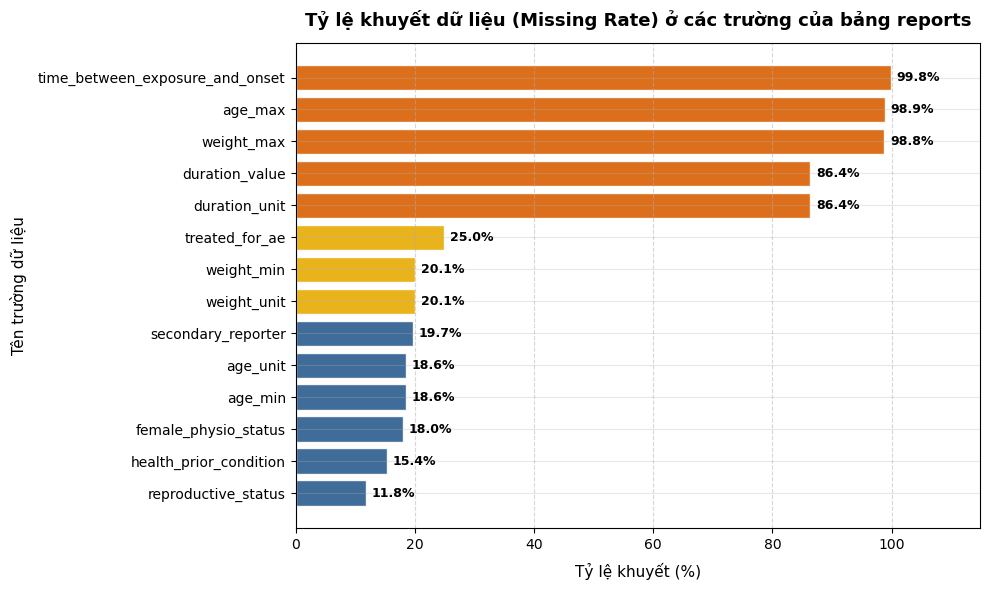

=== MẪU NHÃN PHÂN LOẠI & ĐƠN VỊ ĐO LƯỜNG HỖN HỢP ===

1. Đơn vị tuổi (age_unit):
age_unit
Year     68314
NaN      17525
Month     7298
Week      1175
Day         92
Name: count, dtype: int64

2. Nhãn giới tính (gender) - Lưu ý nhãn 'Unknown' tồn tại song song với NaN:
gender
Male       39599
Female     38637
NaN         9798
Unknown     5777
Mixed        601
Name: count, dtype: int64

3. Nhãn biến mục tiêu serious_ae (Target ML Q6):
serious_ae
false    48855
true     35451
NaN      10106
Name: count, dtype: int64


In [8]:
# 1. Trực quan hóa tỷ lệ khuyết dữ liệu ở các trường cốt lõi trong bảng reports
reports_df = tables["reports"]
fig, ax = plot_missing_overview(
    reports_df,
    title="Tỷ lệ khuyết dữ liệu (Missing Rate) ở các trường của bảng reports",
    top_n=14,
)
plt.show()

# 2. Khảo sát một số nhãn phân loại không nhất quán và đơn vị đo lường hỗn hợp
print("=== MẪU NHÃN PHÂN LOẠI & ĐƠN VỊ ĐO LƯỜNG HỖN HỢP ===")
print("\n1. Đơn vị tuổi (age_unit):")
print(reports_df["age_unit"].value_counts(dropna=False).head(5))

print("\n2. Nhãn giới tính (gender) - Lưu ý nhãn 'Unknown' tồn tại song song với NaN:")
print(reports_df["gender"].value_counts(dropna=False))

print("\n3. Nhãn biến mục tiêu serious_ae (Target ML Q6):")
print(reports_df["serious_ae"].value_counts(dropna=False))


**Nhận xét và phát hiện chính về missing data và nhãn không nhất quán:**

1. **Mức độ khuyết dữ liệu:**
   - **Khuyết gần như tuyệt đối (>98%):** `time_between_exposure_and_onset` (99.84%), `age_max` (98.91%), `weight_max` (98.78%). Lý do: Trong phần lớn hồ sơ, bác sĩ hoặc chủ nuôi chỉ ghi nhận một con số tuổi/cân nặng cụ thể (`age_min`, `weight_min`) thay vì một khoảng dao động min–max.
   - **Khuyết trung bình (10% — 25%):** `duration_*` (86.37%), `treated_for_ae` (24.96%), `weight_min` (20.09%), `age_min` (18.56%), `female_physio_status` (18.00%), `serious_ae` (10.70%), `gender` (10.38%).
   - **Cơ chế khuyết (MAR / MNAR):** Dữ liệu không khuyết hoàn toàn ngẫu nhiên (MCAR). Việc khuyết cân nặng hay tuổi phụ thuộc vào đối tượng gửi báo cáo (`primary_reporter`): các báo cáo từ Bác sĩ thú y (*Veterinarian*) có độ đầy đủ lâm sàng cao hơn hẳn so với báo cáo tự phát từ Chủ vật nuôi (*Animal Owner*).

2. **Nhãn không nhất quán và giá trị Placeholder cần xử lý:**
   - **Đơn vị hỗn hợp:** Tuổi được ghi nhận dưới 5 đơn vị khác nhau (`Year`: 68,314 ca; `Month`: 7,298 ca; `Week`: 1,175 ca; `Day`: 92 ca; `Minute`: 4 ca) $ightarrow$ Cần quy đổi chuẩn hóa về năm (`age_years`) ở bước làm sạch.
   - **Nhãn `'Unknown'` tồn tại độc lập với `NaN`:** Ở cột `gender`, ngoài 9,798 giá trị `NaN`, còn có 5,777 giá trị chuỗi ghi rõ `'Unknown'` và 601 ca ghi `'Mixed'` (đàn vật nuôi gồm cả đực lẫn cái). Cần hợp nhất quy ước nhãn.
   - **Biến mục tiêu `serious_ae`:** Ghi nhận 48,855 ca `false` (51.7%), 35,451 ca `true` (37.5%) và 10,106 ca bị khuyết (10.7%). Đối với bài toán học máy, các dòng khuyết nhãn mục tiêu sẽ được loại bỏ khỏi tập train/test để đảm bảo tính chuẩn xác khi đánh giá mô hình.

---
> **TỔNG KẾT MỤC 2.1:** Toàn bộ 4 bảng dữ liệu đã được khảo sát toàn diện về quy mô 94,412 ca qua 5 quý, ý nghĩa một dòng, khóa chính `unique_aer_id_number`, kế hoạch chuyển đổi kiểu dữ liệu, tính toàn vẹn khóa ngoại (0 orphan keys) và các quy luật khuyết dữ liệu. Bộ dữ liệu hoàn toàn sẵn sàng để các thành viên tách nhánh triển khai EDA chuyên sâu phục vụ 6 câu hỏi nghiên cứu ở các phần tiếp theo.


### 2.2. Khám phá các biến số (Numerical Columns)
- Phân phối, trung tâm và độ phân tán của: tuổi vật nuôi (`animal.age`), cân nặng (`animal.weight`), số lượng cá thể bị ảnh hưởng (`number_of_animals_affected`), độ trễ báo cáo (`reporting_delay_days`), số thuốc dùng kèm (`num_drugs`).
- Phát hiện giá trị ngoại lai (IQR, Z-score) và các giá trị vô lý/placeholder (tuổi âm, cân nặng = 0 hoặc cực đại bất thường) kèm hướng xử lý.

In [9]:
# TODO [Giai đoạn 2]: Phân tích thống kê mô tả và trực quan hóa phân phối biến số (sau khi quy đổi đơn vị)


### 2.3. Khám phá các biến phân loại (Categorical Columns)
- Kiểm tra số lượng giá trị phân biệt và tần suất của: `animal.species`, `animal.gender`, `primary_reporter`, `type_of_information`, `serious_ae`, `treated_for_ae`, `drug.route`, `drug.used_according_to_label`, `reaction.veddra_term_name`, `outcome.medical_status`.
- Phát hiện nhãn không nhất quán (in hoa/thường, từ đồng nghĩa) và gom nhóm các danh mục hiếm (`Other`).

In [10]:
# TODO [Giai đoạn 2]: Thống kê tần suất biến phân loại và kiểm tra nhãn không đồng nhất


### 2.4. Phân tích Dữ liệu Khuyết (Missing Data Analysis)
- Số lượng và tỷ lệ % giá trị khuyết trên từng cột.
- Đánh giá cơ chế khuyết (MCAR / MAR / MNAR): ví dụ `onset_date`, `weight`, hoặc `serious_ae` bị khuyết có phụ thuộc vào `primary_reporter` hay `type_of_information` không?
- Chiến lược xử lý cho từng cột (Drop, Impute hay tách thành nhóm `'Unknown'` riêng).

In [11]:
# TODO [Giai đoạn 2]: Bảng tổng hợp tỷ lệ missing và biểu đồ trực quan hóa mẫu khuyết


### 2.5. Mối quan hệ sơ bộ giữa các biến (Relationships)
- Tương quan giữa các biến số và bảng chéo (cross-tabulations) giữa các tổ hợp quan trọng (`species` $\times$ `serious_ae`, `type_of_information` $\times$ `primary_reporter`, xu hướng số lượng báo cáo theo quý từ 2025Q1 đến 2026).

In [12]:
# TODO [Giai đoạn 2]: Ma trận tương quan và cross-tabulation sơ bộ


### 2.6. Tổng kết Khám phá Dữ liệu & Kế hoạch Tiền xử lý (EDA Summary & Preprocessing Plan)
1. **3–5 Quan sát cốt lõi (Key Observations):** *(Cập nhật sau khi chạy dữ liệu)*
2. **Các vấn đề chất lượng dữ liệu nghiêm trọng (Serious Data Quality Issues):** *(Đơn vị tuổi/cân nặng hỗn hợp, cấu trúc 1-nhiều lồng nhau, tỷ lệ khuyết ở các trường tùy chọn...)*
3. **Kế hoạch Tiền xử lý chuẩn hóa (Preprocessing Plan):** Lưu các bảng đã làm sạch vào `data/processed/` để sử dụng thống nhất cho Notebook 02 và Notebook 03.

In [13]:
# TODO [Giai đoạn 2]: Lưu dữ liệu đã chuẩn hóa cơ bản vào ../data/processed/
